# Clustering jerárquico

El notebook 03 dejó una objeción abierta: tanto FFT como K-Means exigen que fijes $K$ **antes** de
empezar, y vimos en la sección 13 que decidir $K$ es justamente lo difícil.

Los métodos **jerárquicos** dan la vuelta al problema: construyen la jerarquía completa de
agrupamientos, desde $n$ grupos de un elemento hasta un solo grupo con todo, y dejan la elección
de $K$ para el final, cortando el árbol a la altura que te convenga.

## Al terminar deberías poder

1. Explicar la diferencia entre un método jerárquico y uno particional.
2. Leer un dendrograma: qué significan la altura de un nodo y el orden de las uniones.
3. Elegir un criterio de unión (`linkage`) y justificar la elección.
4. Cortar el dendrograma para obtener $K$ grupos con `fcluster`.

**Prerrequisitos**: notebooks 02 (distancias) y 03 (medidas de calidad).


## 0. Preparación

In [ ]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, load_iris
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

src = os.path.join(os.getcwd(), 'src')
if src not in sys.path:
    sys.path.append(src)
from SimpleClustering import plotClusters, euclidiana

## 1. Jerárquico frente a particional

Un algoritmo **particional** crea el conjunto de clusters dividiendo los objetos en grupos
disjuntos. Los métodos **jerárquicos** permiten la existencia de subgrupos, es decir, grupos
anidados.

El proceso jerárquico puede verse como un árbol binario (**dendrograma**) en el que las hojas son
los clusters que contienen un solo elemento, los nodos internos representan la unión de sus dos
hijos, y la raíz es un único cluster que contiene todos los objetos de la colección.


| |
|:--:|
| 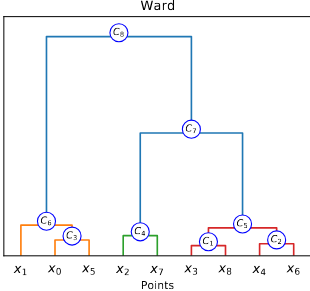 |
|**Dendrograma (Clustering Jerárquico)**|

Los métodos jerárquicos pueden construirse de forma aglomerativa o divisiva. En ambos casos, el proceso de agrupamiento puede describirse mediante el dendrograma, donde las hojas son los grupos que contienen un solo elemento. Los nodos internos representan la unión de sus dos hijos (aglomeración) o la división de un nodo padre (división). La raíz es un clúster único que contiene todos los objetos de la colección. El dendrograma representa una estructura jerárquica para los datos. Este es más informativo que el agrupamiento por algoritmos particionales. La agrupación jerárquica tiene la ventaja de que no necesariamente se requiere el número de grupos $K$ como parámetro de entrada. Además, los algoritmos jerárquicos suelen ser deterministas (es decir, se logra la misma jerarquía para el mismo conjunto de entradas-salidas). Sin embargo, son más costosos que los algoritmos particionales: construir la jerarquía requiere la matriz de distancias completa de $n \times n$ que vimos en el notebook 02, con costo al menos $O(n^2)$ en memoria. Por eso no se usan en colecciones grandes, y por eso existe K-Means.

En la siguiente sección describiremos brevemente en qué consiste una estrategia aglomerativa.

## 2. Criterios de unión (linkage)
El criterio de unión define qué medida se utiliza para decidir qué grupos unir en cada nivel del dendrograma. Es una decisión aparte de la función de distancia: primero eliges cómo comparar dos **puntos** (notebook 02) y luego cómo comparar dos **grupos**. Suponga que dos elementos $x_i$ y $x_j$ tal que  $x_i \in G_p$, $x_j \in G_q$ y  $c_p$, $c_q$ son la media geométrica(centroide) de los grupos $G_p$ y  $G_q$ respectivamente.  Se puede elegir que clusters mezclar mediante alguno de los siguientes criterios:

- **Single** (vecino más cercano): une los dos clusters $G_p$ y $G_q$ que contienen el par $(x_i, x_j)$ cuya distancia es mínima. Tiende a producir grupos alargados en cadena.

- **Complete** (vecino más lejano): se eligen $G_p$ y $G_q$ tales que la mayor distancia entre sus elementos sea la menor posible. Produce grupos compactos.
- **Average**: usa la distancia promedio entre todos los pares. Un punto medio entre single y complete.
- **Centroid**: se unen $G_p$ y $G_q$ tales que la distancia entre sus centroides es mínima.
- **Ward**: se unen los dos clusters que minimizan el incremento de la varianza total, es decir, del $SSE$ del notebook 03. Es el criterio más parecido en espíritu a K-Means, y suele ser el mejor punto de partida.

## 3. Un ejemplo con scipy

#### scipy
La biblioteca scipy proporciona una implementación eficiente de clustering jerárquico que permite utilizar diferentes criterios de `linkage` y generar un dendograma de los datos. El modulo se encuentra en `scipy.cluster.hierarchy`. A continuación presentamos un ejemplo de cómo se utiliza la librería. Trabajamos con solo 10 puntos para que el dendrograma se pueda leer punto por punto.  

In [ ]:
# Generamos un ejemplo pequeño, con tres grupos y 10 puntos
X, etiquetas = make_blobs(n_samples=10, random_state=5)
plotClusters(X, etiquetas)
for i, (px, py) in enumerate(X):
    plt.annotate(f"${i}$", (px + 0.5, py), ha='center', size=12)
plt.show()


In [ ]:
def anota_dendrograma(D, ax, n=None):
      bbox_props = dict(fc="white", ec="b",boxstyle='circle')
      if n is None: n = len(X)
      ll=sorted(set(np.array(D['dcoord']).flatten()))
      for j, d in zip(D['icoord'], D['dcoord']):
        x = 0.5 * sum(j[1:3])
        y = d[1]
        #plt.plot(x, y, 'sr', markersize=10)
        ax.annotate("$C_{%d}$" %(ll.index(y)+n-1), (x, y), xytext=(0, 8),
                    textcoords='offset points', va='top', size=9,
                    ha='center', bbox=bbox_props)


Comparemos los cinco criterios sobre los mismos 10 puntos. Fíjate en que **no dan el mismo
árbol**: el criterio de unión no es un detalle cosmético.


In [ ]:
# Obtenemos distintos agrupamientos y graficamos el dendrograma
fig,axes=plt.subplots(1,5, figsize=(16,5))
axes[0].set_ylabel('Distancia')
for i,lk in enumerate(('ward','centroid','single','complete','average')):
      Z=linkage(X,lk)
      Dz=dendrogram(Z,ax=axes[i])
      axes[i].set_title(lk)
      anota_dendrograma(Dz,axes[i])


En el dendrograma la **altura** de cada nodo representa el costo (distancia) de unir los clusters correspondientes: mientras más alto se une algo, más distintos eran los grupos que se fusionaron. Para el ejemplo, en el caso de complete unir 4 y 8 tiene un coste similar a unir 5 y 7, pero unir $C_{16}$  y $C_{13}$ es más costoso.

La matriz $Z$ devuelta por `linkage` es de dimensión $(n-1) \times 4$. En la $i$-ésima iteración, los grupos con índices $Z_{i,0}$ y $Z_{i,1}$ son combinados para formar un nuevo grupo. $Z_{i, 2}$ es la distancia entre los grupos $Z_{i,0}$ y $Z_{i, 1}$. El cuarto valor $Z_{i, 3}$ representa el número de observaciones originales en el grupo recién formado.

In [ ]:
Z = linkage(X, 'average')  # la ultima Z del ciclo anterior
print("En la ultima iteracion se unen los clusters:", (Z[8,0], Z[8,1]))
print("El costo es de:", Z[8,2])
print("El numero de elementos en el grupo resultante es:", Z[8,3])

Graficar la tercera columna de $Z$, el costo de cada unión, da una lectura rápida de la
estructura: un salto grande indica que se están uniendo grupos que en realidad estaban lejos.


In [ ]:
plt.plot(Z[:,2], marker='o')
plt.xlabel('iteracion'); plt.ylabel('costo de la union')
plt.title('Costo de cada fusion')
plt.show()

## 4. Cortar el dendrograma
El dendrograma muestra la jerarquía completa, pero también puede utilizarse para determinar el número de clusters y los elementos de cada uno. Esto se consigue mediante un **corte horizontal** a una altura determinada: el número de ramas que cruzan la línea de corte es el número de clusters. Aquí está la ventaja frente a K-Means: la jerarquía se calcula **una sola vez** y luego puedes probar todos los valores de $K$ sin volver a agrupar.


In [ ]:
# cortando a una altura de 6 tendriamos dos clusters
Z=linkage(X,'ward')
Dz=dendrogram(Z)
plt.axhline(6,0,10,linestyle='dashed')
anota_dendrograma(Dz,plt)
plt.show()

In [ ]:
# cortando a una altura de 3 tendriamos tres clusters
Z=linkage(X,'ward')
Dz=dendrogram(Z,color_threshold=3) # color_threshold marca la altura de corte (3 clusters, 3 colores)
plt.axhline(3,0,10,linestyle='dashed')
anota_dendrograma(Dz,plt)
plt.show()

In [ ]:
# Podemos obtener las etiquetas de los grupos mediante la funcion fcluster
K=3 # este seria el numero de clusters
yp=fcluster(Z, K, criterion='maxclust') # semejante a predict
print(yp)
plotClusters(X,yp)
plt.show()

In [ ]:
# Para dos clusters, sin recalcular la jerarquia
yp=fcluster(Z, 2, criterion='maxclust')
plotClusters(X,yp)
plt.show()

## 5. Sobre iris, y comparación con el notebook 03

Cerremos aplicando lo anterior a iris y contrastando con lo que obtuvimos con K-Means.


In [ ]:
iris = load_iris()
Xi, yi = iris['data'], iris['target']

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, lk in zip(axes, ['ward', 'complete', 'average', 'single']):
    Zi = linkage(Xi, lk)
    dendrogram(Zi, ax=ax, no_labels=True, color_threshold=0)
    yp = fcluster(Zi, 3, criterion='maxclust')
    ax.set_title('%s\nARI=%.3f  silueta=%.3f]'
                 % (lk, adjusted_rand_score(yi, yp), silhouette_score(Xi, yp)))
plt.tight_layout(); plt.show()

Compara estos números con los del notebook 03: K-Means sobre iris con $K=3$ da un ARI de 0.730.
`ward` da 0.731 y `average` 0.759, es decir, prácticamente lo mismo por un camino
completamente distinto. `complete` baja a 0.642 y `single` a 0.564.

Pero el ARI no es lo que mejor delata a `single`: míralo en los tamaños de los grupos.


`single` produce un grupo de 2 elementos y otro de 98. No encontró tres especies: encontró
setosa, un par de puntos atípicos, y todo lo demás junto. Es el comportamiento que anticipamos en
la sección 2: `single` encadena puntos vecinos, y como versicolor y virginica se tocan, los une
en un solo grupo alargado.

Este es el mismo fenómeno que la matriz de distancias del notebook 02 ya mostraba: el traslape
entre esas dos especies. Cambia el algoritmo, no el problema.


In [ ]:
# El tamaño de cada grupo lo deja en evidencia
for lk in ['ward', 'single']:
    yp = fcluster(linkage(Xi, lk), 3, criterion='maxclust')
    print('%-9s tamaños de los grupos: %s' % (lk, np.bincount(yp)[1:]))

## 6. Ejercicios

1. Repite la comparación de la sección 5 estandarizando `Xi` con `StandardScaler`
   (notebook 02, sección 7). ¿Cambian los ARI? ¿Cambia el orden entre los criterios?
2. Usa `fcluster` con `criterion='distance'` en lugar de `'maxclust'` para cortar a una altura
   fija. ¿Cuántos grupos obtienes con `ward` a la altura 10? ¿Y a la 5?
3. Calcula la silueta de `ward` sobre iris para $K$ de 2 a 10 y compárala con la gráfica de
   K-Means del notebook 03, sección 13. ¿Los dos métodos sugieren el mismo $K$?
4. Para la tarea del notebook 03 necesitas al menos una estrategia jerárquica: elige un criterio
   de unión, justifica la elección con lo visto aquí y repórtalo junto con FFT y K-Means.
